# Identification drift over time

# Imports

In [1]:
import os
from tqdm import tqdm
import numpy as np
import pandas as pd
from pathlib import Path
import anndata

tqdm.pandas()

# 0. Path Configuration

In [4]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

FIGURES_OUT = NOTEBOOK_DIR / "../../Figures"
FIGURES_OUT = FIGURES_OUT.resolve()
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

# Overwrite with environment variable
FIGURES_OUT = Path(os.environ.get("SCI_FIGURES_DIR", FIGURES_OUT))
print(f"Figures directory: {FIGURES_OUT}")

ANNDATA_IN = os.path.join(
    ROOT_OUT,
    'AnnData'
)

Output directory: /home/sam/SCI/SCI/Data
Figures directory: /home/sam/SCI/SCI/Figures


# 1. Load data

In [5]:
adata_precursor = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_precursor.h5ad')
)
adata_protein = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_protein.h5ad')
)

In [2]:
from __future__ import annotations

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns

from SCI_py.constants.plotting import CONDITION_ORDER, CONDITION_COLORS, LAB_COLORS, LAB_ORDER
from SCI_py.plot.utilities import _save, _save_legend

_DATE_COL = 'comment[Gradient time]_date'


def plot_precursors_by_day(
    adata,
    lab:        str,
    count_col:  str              = 'n_precursors',
    conditions: list[str]        = CONDITION_ORDER,
    normalize:  bool             = False,
    save_dir:   str | None       = None,
    filename:   str              = 'precursors_by_day.png',
    show:       bool             = True,
) -> None:
    """
    Plot per-condition precursor counts by acquisition day for a single lab.

    Parameters
    ----------
    adata:
        AnnData with ``plate_idx``, ``source name``, ``count_col``, and
        ``comment[Gradient time]_date`` in ``obs``.
    lab:
        Lab identifier matching ``plate_idx``.
    count_col:
        Column in ``obs`` containing the count to plot.
    conditions:
        Conditions to include.
    normalize:
        If ``True``, normalise counts to % of max per condition.
    save_dir:
        Directory for saved figures.
    filename:
        Output filename.
    show:
        Whether to call ``plt.show()``.
    """
    df = adata.obs[
        adata.obs['plate_idx'].eq(lab) &
        adata.obs['source name'].isin(conditions)
    ].copy()

    day_order = sorted(df[_DATE_COL].dropna().unique())
    if not day_order:
        print(f'No data for {lab}')
        return

    df['date_label'] = df[_DATE_COL].astype(str).str[:10]
    day_order_str    = [str(d)[:10] for d in day_order]

    if normalize:
        for cond in conditions:
            mask    = df['source name'] == cond
            max_val = df.loc[mask, count_col].max()
            if max_val > 0:
                df.loc[mask, count_col] = df.loc[mask, count_col] / max_val * 100

    ylabel = f'% of max {count_col}' if normalize else f'# {count_col}'

    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    sns.boxplot(
        data      = df.sort_values(_DATE_COL),
        x         = 'source name', y=count_col,
        hue       = 'date_label', hue_order=day_order_str,
        order     = [c for c in CONDITION_ORDER if c in conditions],
        palette   = sns.color_palette('Blues', n_colors=len(day_order)),
        ax        = ax,
    )
    ax.set(xlabel='', ylabel=ylabel, title=lab)
    ax.title.set_fontweight('bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.get_legend().remove()

    if save_dir:
        _save(fig, f'{save_dir}/{filename}')
        _save_legend(ax, save_dir, filename.replace('.png', '_legend.png'))

    plt.show() if show else plt.close(fig)


def plot_precursor_stability(
    adata,
    count_col:  str        = 'n_precursors',
    conditions: list[str]  = CONDITION_ORDER,
    save_dir:   str | None = None,
    filename:   str        = 'precursor_stability.png',
    show:       bool       = True,
) -> None:
    """
    Plot normalised precursor counts over relative acquisition days per lab.

    Parameters
    ----------
    adata:
        AnnData with ``plate_idx``, ``source name``, ``count_col``, and
        ``comment[Gradient time]_date`` in ``obs``.
    count_col:
        Column in ``obs`` containing the count to plot.
    conditions:
        Conditions to include, each shown as a separate subplot.
    save_dir:
        Directory for saved figures.
    filename:
        Output filename.
    show:
        Whether to call ``plt.show()``.
    """
    condition_order = [c for c in CONDITION_ORDER if c in conditions]
    combined        = _build_stability_df(adata, count_col, condition_order)

    if combined.empty:
        print('No data available.')
        return

    fig, axes = plt.subplots(
        1, len(condition_order),
        figsize=(6 * len(condition_order), 5),
        sharey=True, constrained_layout=True,
    )
    axes = [axes] if len(condition_order) == 1 else list(axes)

    for ax, cond in zip(axes, condition_order):
        cond_df = combined[combined['source name'] == cond]
        for lab in LAB_ORDER:
            lab_groups = cond_df[cond_df['plate_idx'] == lab].groupby('day_relative')[f'{count_col}_pct']
            if lab_groups.ngroups == 0:
                continue
            median = lab_groups.median()
            q25    = lab_groups.quantile(0.25)
            q75    = lab_groups.quantile(0.75)
            color  = LAB_COLORS.get(lab, 'black')
            ax.plot(median.index, median.values, color=color, linewidth=2, label=lab)
            ax.fill_between(median.index, q25.values, q75.values, color=color, alpha=0.15)

        ax.set(xlabel='Days since first acquisition',
               ylabel=f'% of max {count_col}' if ax == axes[0] else '',
               title=cond, xlim=(0, None))
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.title.set_fontweight('bold')
        ax.spines[['top', 'right']].set_visible(False)

    fig.suptitle(f'{count_col} stability over time', fontweight='bold')

    if save_dir:
        _save(fig, f'{save_dir}/{filename}')
        _save_stability_legend(save_dir, filename)

    plt.show() if show else plt.close(fig)


# ---------------------------------------------------------------------------
# Private helpers
# ---------------------------------------------------------------------------

def _build_stability_df(adata, count_col, condition_order) -> pd.DataFrame:
    dfs = []
    for lab in LAB_ORDER:
        df = adata.obs[
            adata.obs['plate_idx'].eq(lab) &
            adata.obs['source name'].isin(condition_order)
        ].copy().dropna(subset=[_DATE_COL])

        if df.empty:
            continue

        df[_DATE_COL]      = pd.to_datetime(df[_DATE_COL])
        df['day_relative'] = (df[_DATE_COL] - df[_DATE_COL].min()).dt.days.astype(int)

        for cond in condition_order:
            mask    = df['source name'] == cond
            max_val = df.loc[mask, count_col].max()
            if max_val > 0:
                df.loc[mask, f'{count_col}_pct'] = df.loc[mask, count_col] / max_val * 100

        dfs.append(df)

    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()


def _save_stability_legend(save_dir, filename):
    handles = [
        mlines.Line2D([], [], color=LAB_COLORS.get(lab, 'black'), linewidth=2, label=lab)
        for lab in LAB_ORDER
    ]
    fig, ax = plt.subplots(figsize=(4, len(LAB_ORDER) * 0.4 + 0.5))
    ax.legend(handles=handles, title='Lab', loc='center', frameon=False, fontsize=9)
    ax.axis('off')
    _save(fig, f'{save_dir}/{filename.replace(".png", "_legend.png")}')
    plt.close(fig)

In [10]:
adata_protein.var.reset_index()

,PG.ProteinGroups,PG.ProteinAccessions,PEP.StrippedSequence,PEP.IsProteotypic,EG.ModifiedSequence,FG.Charge,FG.LabeledSequence,FG.PrecursorIon,PG.Qvalue,FG.Qvalue,...,completeness_feature_timsTOF_3_SC,completeness_feature_Astral_1_QC,completeness_feature_Astral_2_QC,completeness_feature_Astral_3_QC,completeness_feature_Astral_4_QC,completeness_feature_Astral_5_QC,completeness_feature_Astral_6_QC,completeness_feature_timsTOF_1_QC,completeness_feature_timsTOF_2_QC,completeness_feature_timsTOF_3_QC
0,sp|A0A075B6H7|KV37_HUMAN;sp|A0A0C4DH55|KVD07_H...,A0A075B6H7;A0A0C4DH55;P01624,LLIYGASTR,False,_LLIYGASTR_,2,LLIYGASTR,LLIYGASTR/2,0.001578,0.000789,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00
1,sp|A0A075B6S2|KVD29_HUMAN,A0A075B6S2,FSGSGSGTDFTLK,False,_FSGSGSGTDFTLK_,2,FSGSGSGTDFTLK,FSGSGSGTDFTLK/2,0.001578,0.000057,...,0.004630,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00
2,sp|A0A087X1C5|CP2D7_HUMAN;sp|P10635|CP2D6_HUMAN,A0A087X1C5;P10635,LLDLAQEGLK,False,_LLDLAQEGLK_,2,LLDLAQEGLK,LLDLAQEGLK/2,0.001578,0.000569,...,0.000000,0.977778,0.000000,0.00000,0.978261,0.000000,0.000000,0.000000,0.000000,0.00
3,sp|A0A0A0MRZ8|KVD11_HUMAN;sp|P04433|KV311_HUMAN,A0A0A0MRZ8;P04433,LLIYDASNR,False,_LLIYDASNR_,2,LLIYDASNR,LLIYDASNR/2,0.001524,0.001390,...,0.000000,0.000000,0.000000,0.00000,0.021739,0.000000,0.000000,0.000000,0.000000,0.00
4,sp|A0A0B4J1V1|HV321_HUMAN;sp|A0A0B4J1X8|HV343_...,A0A0B4J1V1;A0A0B4J1X8;A0A0C4DH32;P01762;P01763...,NSLYLQMNSLR,False,_NSLYLQM[Oxidation (M)]NSLR_,2,NSLYLQM[Oxidation (M)]NSLR,NSLYLQM[UNIMOD:35]NSLR/2,0.001578,0.001046,...,0.004630,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7226,tr|Cont_Q2KJC7|Q2KJC7_BOVIN,Cont_Q2KJC7,IIDGVPVEITEK,False,_IIDGVPVEITEK_,2,IIDGVPVEITEK,IIDGVPVEITEK/2,0.001524,0.000335,...,0.000000,0.977778,1.000000,1.00000,0.978261,1.000000,1.000000,1.000000,0.840909,0.98
7227,tr|Cont_Q2TBQ1|Q2TBQ1_BOVIN,Cont_Q2TBQ1,GPGEITCNR,True,_GPGEITC[Carbamidomethyl (C)]NR_,2,GPGEITC[Carbamidomethyl (C)]NR,GPGEITC[UNIMOD:4]NR/2,0.001578,0.000703,...,0.000000,0.977778,0.934783,0.00000,0.000000,0.478261,0.666667,0.000000,0.386364,0.56
7228,tr|Cont_Q32PI4|Q32PI4_BOVIN,Cont_Q32PI4,EAAEMLTADMDAER,True,_EAAEM[Oxidation (M)]LTADM[Oxidation (M)]DAER_,2,EAAEM[Oxidation (M)]LTADM[Oxidation (M)]DAER,EAAEM[UNIMOD:35]LTADM[UNIMOD:35]DAER/2,0.001524,0.001111,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.044444,0.000000,0.000000,0.00
7229,tr|Cont_Q3MHH8|Q3MHH8_BOVIN,Cont_Q3MHH8,SYDVAYQVR,True,_SYDVAYQVR_,2,SYDVAYQVR,SYDVAYQVR/2,0.001524,0.000823,...,0.041667,0.977778,1.000000,0.76087,0.978261,0.913043,0.911111,0.782609,0.795455,0.64


In [15]:
adata_precursor.var

,PG.ProteinGroups,PG.ProteinAccessions,PEP.StrippedSequence,PEP.IsProteotypic,EG.ModifiedSequence,FG.Charge,FG.LabeledSequence,PG.Qvalue,FG.Qvalue,EG.GlobalPrecursorQvalue,...,completeness_feature_timsTOF_3_SC,completeness_feature_Astral_1_QC,completeness_feature_Astral_2_QC,completeness_feature_Astral_3_QC,completeness_feature_Astral_4_QC,completeness_feature_Astral_5_QC,completeness_feature_Astral_6_QC,completeness_feature_timsTOF_1_QC,completeness_feature_timsTOF_2_QC,completeness_feature_timsTOF_3_QC
FG.PrecursorIon,,,,,,,,,,,,,,,,,,,,,
AAAAAAAAAASGAAIPPLIPPR/3,sp|O14654|IRS4_HUMAN,O14654,AAAAAAAAAASGAAIPPLIPPR,True,_AAAAAAAAAASGAAIPPLIPPR_,3,AAAAAAAAAASGAAIPPLIPPR,0.001578,8.413650e-04,0.000367,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.00
AAAAAAAAAPAAAATAPTTAATTAATAAQ/3,sp|P37108|SRP14_HUMAN,P37108,AAAAAAAAAPAAAATAPTTAATTAATAAQ,True,_AAAAAAAAAPAAAATAPTTAATTAATAAQ_,3,AAAAAAAAAPAAAATAPTTAATTAATAAQ,0.001524,2.739516e-04,0.000371,...,0.004630,0.000000,0.000000,0.000000,0.717391,0.0,0.000000,0.608696,0.590909,0.92
AAAAAAAAAVSR/2,sp|Q96JP5|ZFP91_HUMAN,Q96JP5,AAAAAAAAAVSR,True,_AAAAAAAAAVSR_,2,AAAAAAAAAVSR,0.001578,3.216908e-03,0.000337,...,0.000000,0.000000,0.913043,0.652174,0.000000,0.0,0.822222,0.000000,0.000000,0.00
AAAAAAALQAK/2,sp|P36578|RL4_HUMAN,P36578,AAAAAAALQAK,True,_AAAAAAALQAK_,2,AAAAAAALQAK,0.001524,2.697230e-06,0.000367,...,0.986111,0.977778,1.000000,1.000000,0.978261,1.0,1.000000,1.000000,0.840909,0.98
AAAAAATVLLR/2,sp|O60779|S19A2_HUMAN,O60779,AAAAAATVLLR,True,_AAAAAATVLLR_,2,AAAAAATVLLR,0.001578,6.154260e-04,0.000701,...,0.000000,0.000000,0.913043,0.000000,0.000000,0.0,0.733333,0.000000,0.000000,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
[UNIMOD:1]VHFTAEEK/2,sp|P02100|HBE_HUMAN,P02100,VHFTAEEK,True,_[Acetyl (Protein N-term)]VHFTAEEK_,2,[Acetyl (Protein N-term)]VHFTAEEK,0.001524,1.314672e-07,0.000337,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.00
[UNIMOD:1]VNFTVDQIR/2,sp|P13639|EF2_HUMAN,P13639,VNFTVDQIR,True,_[Acetyl (Protein N-term)]VNFTVDQIR_,2,[Acetyl (Protein N-term)]VNFTVDQIR,0.001524,2.577994e-04,0.000701,...,0.013889,0.000000,0.760870,0.000000,0.000000,0.0,0.911111,0.000000,0.000000,0.28
[UNIMOD:1]VNPTVFFDIAVDGEPLGR/2,sp|P62937|PPIA_HUMAN,P62937,VNPTVFFDIAVDGEPLGR,True,_[Acetyl (Protein N-term)]VNPTVFFDIAVDGEPLGR_,2,[Acetyl (Protein N-term)]VNPTVFFDIAVDGEPLGR,0.001524,8.203785e-03,0.000367,...,0.578704,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.108696,0.000000,0.00


In [ ]:
adata_protein.var['Contaminant'] = adata_protein.var.index.apply(lambda x: 'sp|Cont' in x)

AttributeError: 'AnnData' object has no attribute 'index'

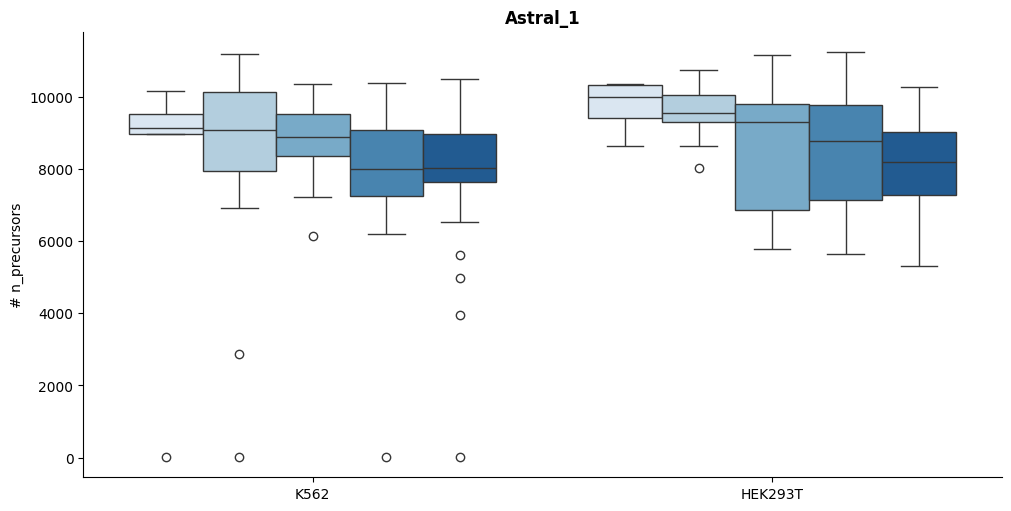

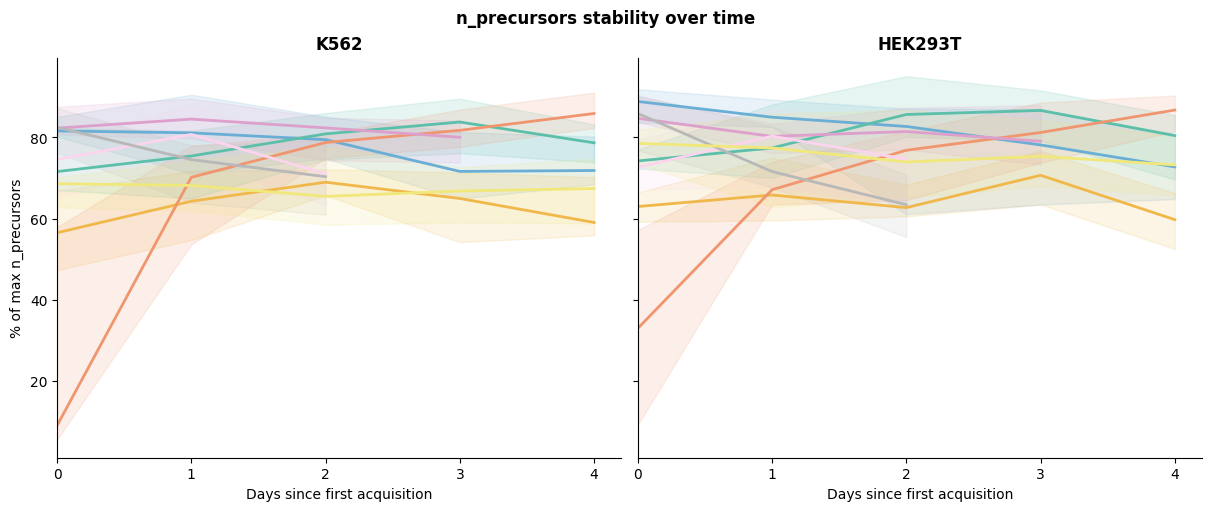

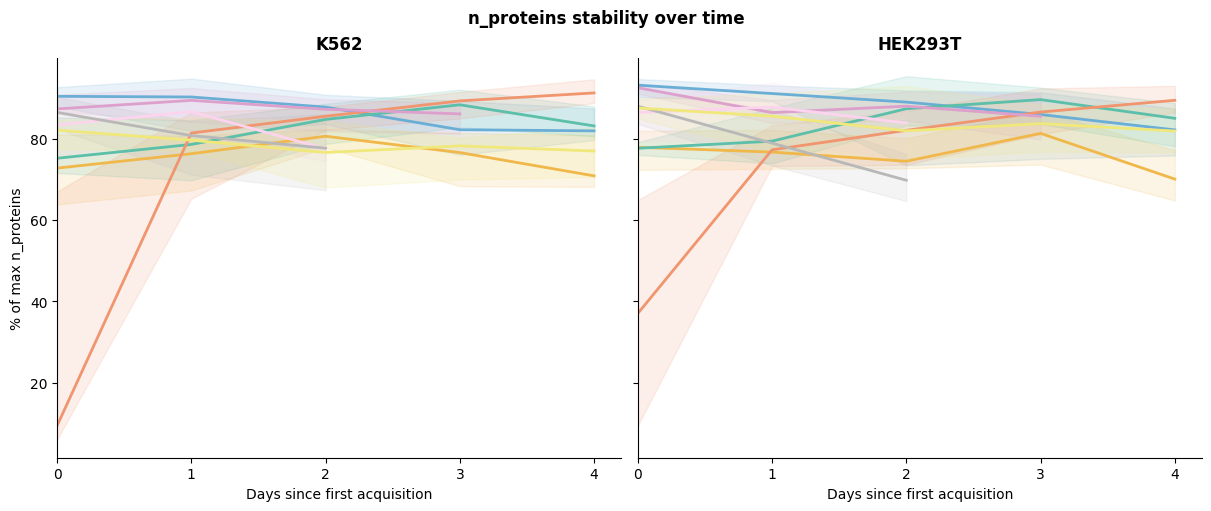

In [ ]:
conditions = ['K562', 'HEK293T', 'Site specific QC', 'QC - Hela']

# Single lab, by day
plot_precursors_by_day(
    adata_precursor,
    lab='Astral_1',
    conditions=['K562', 'HEK293T'],
    save_dir=False
)

# All labs, stability over time
plot_precursor_stability(
    adata_precursor,
    lab='Astral_1',
    conditions=['K562', 'HEK293T'],
    save_dir=False
)

# Using proteins instead
plot_precursor_stability(
    adata_protein,
    count_col='n_proteins',
    conditions=['K562', 'HEK293T'],
    save_dir=False
)

# 3. Drift within a day

# 4. Correlation strength of drift